# Practical Assignment 6: Clustering Algorithms
## From-Scratch and Library Implementations

**Dataset:** Wine Recognition dataset (scikit-learn)  
**Student:** Paras Satpute  
**Task:** Discover meaningful groups without using class labels during clustering.

## 1. Abstract and objectives

This practical explores unsupervised clustering on the Wine Recognition dataset. Three algorithms are implemented in two ways: (1) manually using NumPy/Python and (2) using scikit-learn. The algorithms are K-Means, DBSCAN and agglomerative hierarchical clustering. Their outputs are evaluated using the Silhouette Coefficient, Davies–Bouldin Index and Calinski–Harabasz Index, alongside cluster sizes, noise coverage and PCA visualisations.

**Objectives**
1. Understand the dataset and prepare numeric features for distance-based clustering.
2. Implement K-Means from scratch and compare it with `sklearn.cluster.KMeans`.
3. Implement DBSCAN from scratch and compare it with `sklearn.cluster.DBSCAN`.
4. Implement single-link agglomerative clustering from scratch and compare it with scikit-learn.
5. Select parameters using internal clustering metrics and visual inspection.
6. Discuss strengths, weaknesses, practical use cases, ethical issues and future improvements.

**Important experimental rule:** the Wine target labels are not used to fit algorithms, choose parameters or calculate the internal clustering scores. Clustering is unsupervised; the labels are deliberately excluded from the modelling workflow.

## 2. Theory of the clustering algorithms

### 2.1 K-Means
K-Means partitions observations into `K` clusters. It alternates between assigning each point to its nearest centroid and updating each centroid to the mean of its assigned points. It minimises within-cluster sum of squared distances (inertia).

**From-scratch steps**
1. Initialise `K` centroids using observations selected by k-means++.
2. Assign every observation to the closest centroid.
3. Recompute each centroid as the mean of its assigned observations.
4. Repeat until labels stop changing or the iteration limit is reached.

K-Means works best for compact, roughly spherical clusters. It requires `K` in advance and is sensitive to scaling, outliers and initialisation.

### 2.2 DBSCAN
DBSCAN (Density-Based Spatial Clustering of Applications with Noise) groups points in dense regions. `eps` defines the neighbourhood radius and `min_samples` defines the minimum number of observations needed for a core point. Points not assigned to a density-connected cluster are labelled noise (`-1`).

DBSCAN can discover irregularly shaped clusters and identify noise without specifying the number of clusters. It is sensitive to `eps`, `min_samples` and feature scaling; varying densities can be difficult.

### 2.3 Agglomerative hierarchical clustering
Agglomerative clustering starts with every observation as its own cluster and repeatedly merges the closest pair until the required number of clusters remains. Single linkage defines the distance between two clusters as the minimum pairwise distance between their members.

It produces a hierarchy and can capture non-spherical structures, but single linkage can create chaining effects. A full pairwise implementation is computationally more expensive than centroid-based K-Means.

## 3. Imports and reproducibility

In [1]:
import sys, time, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

SEED = 42
rng = np.random.default_rng(SEED)
print("Python:", sys.version.split()[0], "| scikit-learn:", sklearn.__version__)

Python: 3.13.5 | scikit-learn: 1.8.0


## 4. Load and inspect the dataset

In [2]:
wine = load_wine(as_frame=True)
X_df = wine.data.copy()
y_reference = wine.target.copy()  # Reserved for optional post-hoc comparison only.
feature_names = list(X_df.columns)
print("Feature matrix shape:", X_df.shape)
print("Number of numeric features:", len(feature_names))
display(X_df.head())

Feature matrix shape: (178, 13)
Number of numeric features: 13


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [3]:
print("Descriptive statistics:")
display(X_df.describe().T)
print("Missing values per feature:")
display(X_df.isna().sum().to_frame("missing_count"))

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


Missing values per feature:


,missing_count
alcohol,0
malic_acid,0
ash,0
alcalinity_of_ash,0
magnesium,0
total_phenols,0
flavanoids,0
nonflavanoid_phenols,0
proanthocyanins,0
color_intensity,0


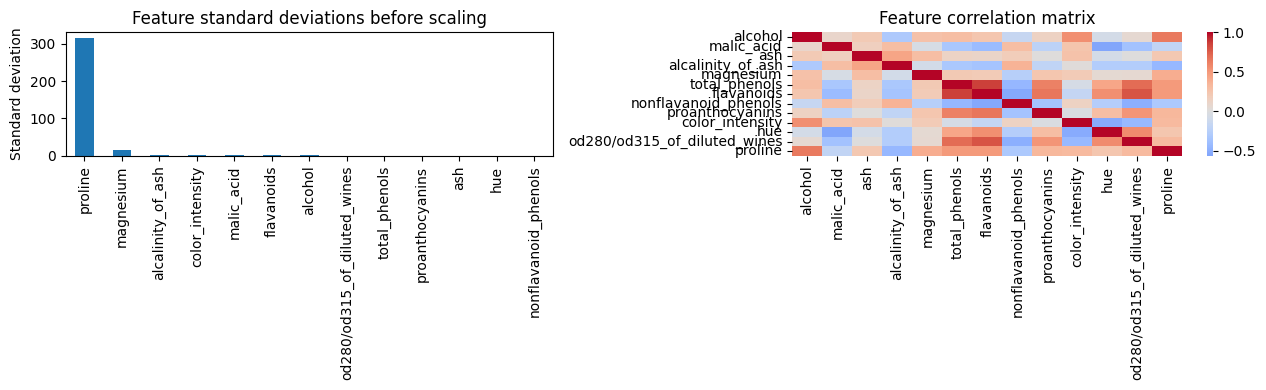

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
X_df.std().sort_values(ascending=False).plot(kind="bar", ax=ax[0])
ax[0].set_title("Feature standard deviations before scaling")
ax[0].set_ylabel("Standard deviation")
sns.heatmap(X_df.corr(), cmap="coolwarm", center=0, ax=ax[1])
ax[1].set_title("Feature correlation matrix")
plt.tight_layout()
plt.show()

### Dataset observations and preparation

The dataset contains continuous chemical measurements on different numeric scales. Euclidean-distance algorithms would allow large-scale features to dominate if the features were used in their original units. Therefore, `StandardScaler` is applied to all 13 feature columns before clustering.

The reference target labels are kept in a separate variable and are not included in `X`, scaling, parameter selection or internal evaluation. They are used only in a clearly marked optional post-hoc external comparison at the end.

In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_df)
print("Scaled matrix:", X_scaled.shape)
print("Feature means (approx. 0):", np.round(X_scaled.mean(axis=0)[:5], 3))
print("Feature standard deviations (approx. 1):", np.round(X_scaled.std(axis=0)[:5], 3))

Scaled matrix: (178, 13)
Feature means (approx. 0): [-0. -0. -0. -0. -0.]
Feature standard deviations (approx. 1): [1. 1. 1. 1. 1.]


## 5. PCA for visual inspection

PCA reduces the standardised 13-dimensional feature matrix to two dimensions for plotting. The clustering algorithms below still operate on the complete 13-dimensional scaled feature matrix; PCA is only a visualisation aid, so dimensionality reduction does not silently change the modelling problem.

Variance explained by PC1 and PC2: [0.362  0.1921]
Total variance explained: 0.5541


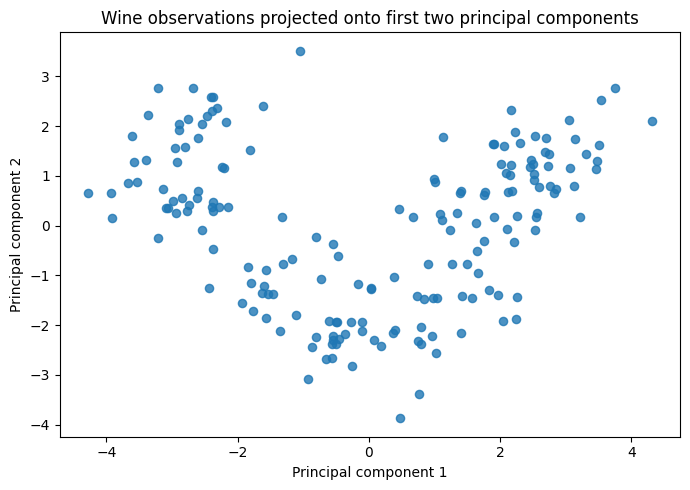

In [6]:
pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_scaled)
print("Variance explained by PC1 and PC2:", np.round(pca.explained_variance_ratio_, 4))
print("Total variance explained:", round(pca.explained_variance_ratio_.sum(), 4))
plt.figure(figsize=(7, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], s=35, alpha=0.8)
plt.xlabel("Principal component 1"); plt.ylabel("Principal component 2")
plt.title("Wine observations projected onto first two principal components")
plt.tight_layout(); plt.show()

## 6. K-Means: implementation from scratch

The implementation below uses k-means++ initialisation, Euclidean distance, centroid updates and a convergence check. Empty clusters are reinitialised to a randomly selected observation. Multiple initialisations are supported; the run with the lowest inertia is retained.

This is a transparent educational implementation. Scikit-learn's implementation is highly optimised and includes additional numerical and performance refinements.

In [7]:
def kmeans_plus_plus_init(X, k, random_state=42):
    rng_local = np.random.default_rng(random_state)
    n = X.shape[0]
    centers = [X[rng_local.integers(n)]]
    for _ in range(1, k):
        d2 = np.min(((X[:, None, :] - np.array(centers)[None, :, :]) ** 2).sum(axis=2), axis=1)
        if d2.sum() == 0:
            idx = rng_local.integers(n)
        else:
            idx = rng_local.choice(n, p=d2 / d2.sum())
        centers.append(X[idx])
    return np.array(centers, dtype=float)

def kmeans_scratch(X, k, n_init=10, max_iter=300, tol=1e-4, random_state=42):
    best = None
    for run in range(n_init):
        centers = kmeans_plus_plus_init(X, k, random_state + run)
        labels = np.zeros(X.shape[0], dtype=int)
        for iteration in range(max_iter):
            distances = np.linalg.norm(X[:, None, :] - centers[None, :, :], axis=2)
            new_labels = distances.argmin(axis=1)
            new_centers = centers.copy()
            for cluster_id in range(k):
                members = X[new_labels == cluster_id]
                if len(members):
                    new_centers[cluster_id] = members.mean(axis=0)
                else:
                    new_centers[cluster_id] = X[np.random.default_rng(random_state + run + iteration + cluster_id).integers(len(X))]
            shift = np.linalg.norm(new_centers - centers)
            stable = np.array_equal(new_labels, labels)
            labels, centers = new_labels, new_centers
            if stable or shift <= tol:
                break
        inertia = float(((X - centers[labels]) ** 2).sum())
        if best is None or inertia < best["inertia"]:
            best = {"labels": labels.copy(), "centers": centers.copy(),
                    "inertia": inertia, "n_iter": iteration + 1}
    return best

### 6.1 Choose K using elbow and silhouette analysis

In [8]:
k_rows = []
scratch_k_models = {}
library_k_models = {}
for k in range(2, 9):
    s = kmeans_scratch(X_scaled, k, n_init=10, random_state=SEED)
    lib = KMeans(n_clusters=k, n_init=20, random_state=SEED)
    lib_labels = lib.fit_predict(X_scaled)
    scratch_k_models[k] = s
    library_k_models[k] = lib
    k_rows.append({
        "K": k,
        "Scratch inertia": s["inertia"],
        "Scratch silhouette": silhouette_score(X_scaled, s["labels"]),
        "Library inertia": lib.inertia_,
        "Library silhouette": silhouette_score(X_scaled, lib_labels)
    })
k_results = pd.DataFrame(k_rows)
display(k_results.round(4))

,K,Scratch inertia,Scratch silhouette,Library inertia,Library silhouette
0,2,1659.0080,0.2683,1658.7589,0.2593
1,3,1277.9285,0.2849,1277.9285,0.2849
2,4,1175.3519,0.2586,1175.3519,0.2586
3,5,1110.8935,0.2237,1107.0073,0.2315
4,6,1053.5509,0.2062,1046.0023,0.2372
5,7,995.1711,0.1972,981.5952,0.2036
6,8,945.5472,0.1675,935.2012,0.1570


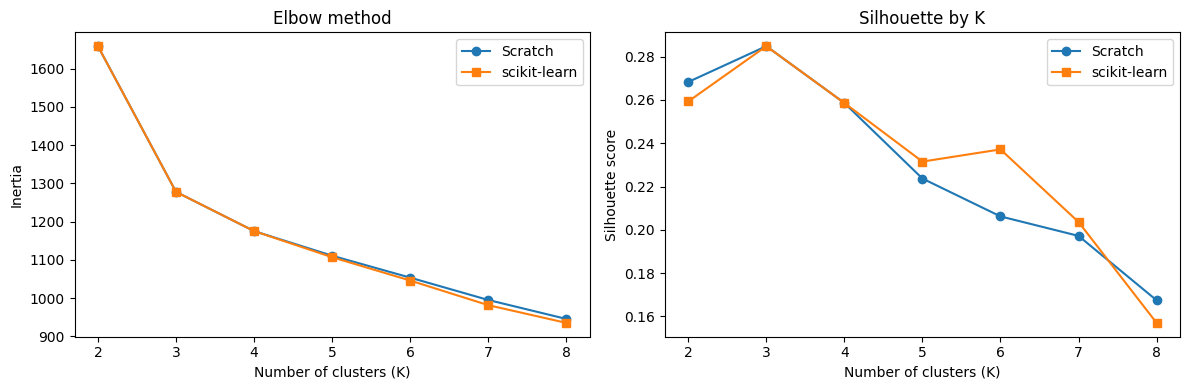

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(k_results["K"], k_results["Scratch inertia"], marker="o", label="Scratch")
ax[0].plot(k_results["K"], k_results["Library inertia"], marker="s", label="scikit-learn")
ax[0].set_xlabel("Number of clusters (K)"); ax[0].set_ylabel("Inertia")
ax[0].set_title("Elbow method"); ax[0].legend()
ax[1].plot(k_results["K"], k_results["Scratch silhouette"], marker="o", label="Scratch")
ax[1].plot(k_results["K"], k_results["Library silhouette"], marker="s", label="scikit-learn")
ax[1].set_xlabel("Number of clusters (K)"); ax[1].set_ylabel("Silhouette score")
ax[1].set_title("Silhouette by K"); ax[1].legend()
plt.tight_layout(); plt.show()

The elbow plot shows how within-cluster sum of squares decreases as K increases. It will always decrease (or remain unchanged) when more centroids are added, so the elbow is a heuristic rather than a standalone proof. The silhouette score measures cohesion and separation, with larger values generally preferred. Select K using the metrics and the practical interpretability of cluster sizes; do not choose K from the reference class labels.

In [10]:
best_k = int(k_results.loc[k_results["Library silhouette"].idxmax(), "K"])
print("Selected K by highest library silhouette among K=2..8:", best_k)

Selected K by highest library silhouette among K=2..8: 3


### 6.2 Compare scratch and library K-Means

In [11]:
t0 = time.perf_counter()
km_scratch = kmeans_scratch(X_scaled, best_k, n_init=20, random_state=SEED)
scratch_km_time = time.perf_counter() - t0

t0 = time.perf_counter()
km_library = KMeans(n_clusters=best_k, n_init=20, random_state=SEED)
km_library_labels = km_library.fit_predict(X_scaled)
library_km_time = time.perf_counter() - t0

km_comparison = pd.DataFrame([
    {"Implementation":"K-Means from scratch", "Clusters":len(np.unique(km_scratch["labels"])),
     "Inertia":km_scratch["inertia"], "Silhouette":silhouette_score(X_scaled,km_scratch["labels"]),
     "Time (s)":scratch_km_time, "Iterations":km_scratch["n_iter"]},
    {"Implementation":"scikit-learn KMeans", "Clusters":len(np.unique(km_library_labels)),
     "Inertia":km_library.inertia_, "Silhouette":silhouette_score(X_scaled,km_library_labels),
     "Time (s)":library_km_time, "Iterations":km_library.n_iter_}
])
display(km_comparison.round(4))

,Implementation,Clusters,Inertia,Silhouette,Time (s),Iterations
0,K-Means from scratch,3,1277.9285,0.2849,0.0168,3
1,scikit-learn KMeans,3,1277.9285,0.2849,0.0161,7


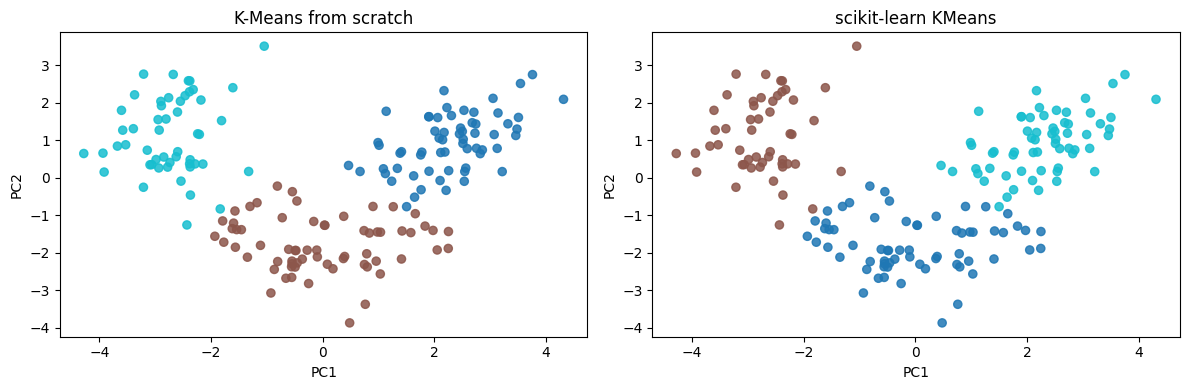

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, labels, title in [
    (ax[0], km_scratch["labels"], "K-Means from scratch"),
    (ax[1], km_library_labels, "scikit-learn KMeans")
]:
    a.scatter(X_pca[:,0], X_pca[:,1], c=labels, cmap="tab10", s=35, alpha=.85)
    a.set_title(title); a.set_xlabel("PC1"); a.set_ylabel("PC2")
plt.tight_layout(); plt.show()

## 7. DBSCAN: implementation from scratch

The implementation computes pairwise Euclidean distances and expands clusters from core points. A point is a core point when its epsilon-neighbourhood contains at least `min_samples` observations (including itself). Border points are assigned to a cluster when density-reachable; points never reached by a cluster are noise (`-1`).

Pairwise distances require O(n²) memory and time, making this simple implementation suitable for this small dataset but not ideal for very large datasets. Scikit-learn offers optimised neighbour-search options.

In [13]:
def dbscan_scratch(X, eps, min_samples):
    n = X.shape[0]
    # Pairwise Euclidean distance matrix
    dist = np.sqrt(((X[:, None, :] - X[None, :, :]) ** 2).sum(axis=2))
    neighborhoods = [np.where(dist[i] <= eps)[0] for i in range(n)]
    core = np.array([len(neigh) >= min_samples for neigh in neighborhoods])
    labels = np.full(n, -1, dtype=int)
    visited = np.zeros(n, dtype=bool)
    cluster_id = 0

    for point in range(n):
        if visited[point]:
            continue
        visited[point] = True
        if not core[point]:
            continue
        labels[point] = cluster_id
        seeds = list(neighborhoods[point])
        seed_set = set(seeds)
        cursor = 0
        while cursor < len(seeds):
            q = seeds[cursor]
            cursor += 1
            if not visited[q]:
                visited[q] = True
                if core[q]:
                    for neighbor in neighborhoods[q]:
                        if int(neighbor) not in seed_set:
                            seeds.append(int(neighbor))
                            seed_set.add(int(neighbor))
            if labels[q] == -1:
                labels[q] = cluster_id
        cluster_id += 1
    return labels

### 7.1 DBSCAN parameter sensitivity

DBSCAN does not require a cluster count. Its output depends on `eps` and `min_samples`. The following grid explores several radii and minimum-neighbour counts. For internal scores, noise points are excluded from the silhouette, Davies–Bouldin and Calinski–Harabasz calculations; the fraction of points retained in non-noise clusters is reported separately. A score is not calculated when fewer than two non-noise clusters remain.

In [14]:
def clustering_metrics(X, labels, noise_label=-1):
    labels = np.asarray(labels)
    keep = labels != noise_label
    y = labels[keep]
    unique = np.unique(y)
    n_clusters = len(unique)
    coverage = float(keep.mean())
    if n_clusters < 2 or keep.sum() <= n_clusters:
        sil = dbi = chi = np.nan
    else:
        sil = silhouette_score(X[keep], y)
        dbi = davies_bouldin_score(X[keep], y)
        chi = calinski_harabasz_score(X[keep], y)
    return {"clusters_excluding_noise":n_clusters, "noise_fraction":1-coverage,
            "coverage":coverage, "silhouette":sil,
            "davies_bouldin":dbi, "calinski_harabasz":chi}

db_rows = []
db_labels_scratch = {}
db_labels_library = {}
for eps in [1.5, 2.0, 2.5, 3.0, 3.5, 4.0]:
    for ms in [3, 5, 8]:
        ls = dbscan_scratch(X_scaled, eps, ms)
        lib = DBSCAN(eps=eps, min_samples=ms)
        ll = lib.fit_predict(X_scaled)
        db_labels_scratch[(eps,ms)] = ls
        db_labels_library[(eps,ms)] = ll
        mscr = clustering_metrics(X_scaled, ls)
        mlib = clustering_metrics(X_scaled, ll)
        db_rows.append({"eps":eps, "min_samples":ms, "Implementation":"Scratch",
                        **mscr})
        db_rows.append({"eps":eps, "min_samples":ms, "Implementation":"Library",
                        **mlib})
db_results = pd.DataFrame(db_rows)
display(db_results.round(4))

,eps,min_samples,Implementation,clusters_excluding_noise,noise_fraction,coverage,silhouette,davies_bouldin,calinski_harabasz
0,1.5,3,Scratch,8,0.8258,0.1742,0.3311,0.9195,25.2729
1,1.5,3,Library,8,0.8258,0.1742,0.3311,0.9195,25.2729
2,1.5,5,Scratch,0,1.0000,0.0000,NaN,NaN,NaN
3,1.5,5,Library,0,1.0000,0.0000,NaN,NaN,NaN
4,1.5,8,Scratch,0,1.0000,0.0000,NaN,NaN,NaN
5,1.5,8,Library,0,1.0000,0.0000,NaN,NaN,NaN
6,2.0,3,Scratch,5,0.3596,0.6404,0.2113,1.3438,20.0559
7,2.0,3,Library,5,0.3596,0.6404,0.2113,1.3438,20.0559
8,2.0,5,Scratch,5,0.4775,0.5225,0.2405,1.0472,18.7506
9,2.0,5,Library,5,0.4775,0.5225,0.2405,1.0472,18.7506


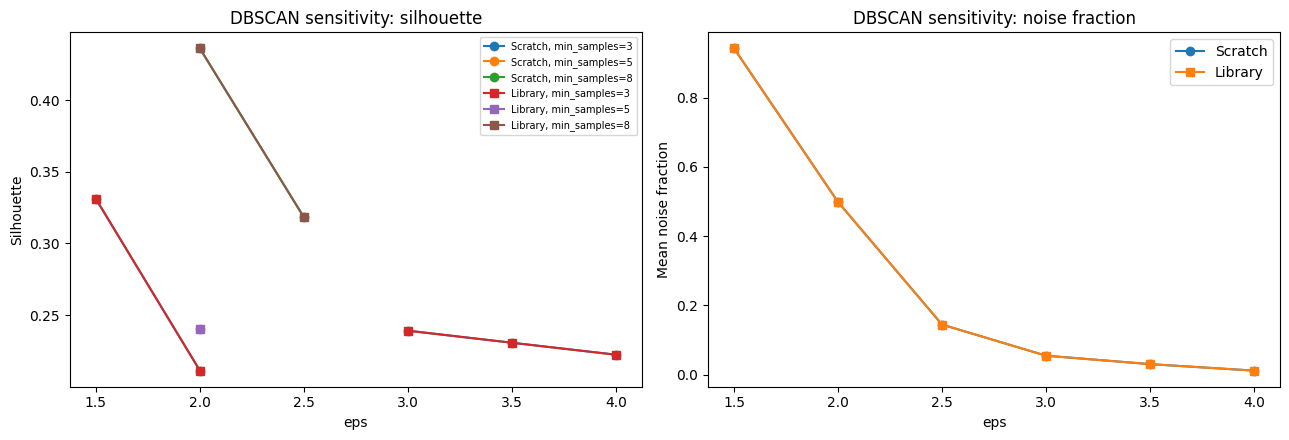

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for impl, marker in [("Scratch","o"),("Library","s")]:
    sub = db_results[db_results["Implementation"] == impl]
    for ms in sorted(sub["min_samples"].unique()):
        q = sub[sub["min_samples"] == ms]
        ax[0].plot(q["eps"], q["silhouette"], marker=marker, label=f"{impl}, min_samples={ms}")
ax[0].set_xlabel("eps"); ax[0].set_ylabel("Silhouette")
ax[0].set_title("DBSCAN sensitivity: silhouette"); ax[0].legend(fontsize=7)
for impl, marker in [("Scratch","o"),("Library","s")]:
    sub = db_results[db_results["Implementation"] == impl]
    q = sub.groupby("eps")["noise_fraction"].mean()
    ax[1].plot(q.index, q.values, marker=marker, label=impl)
ax[1].set_xlabel("eps"); ax[1].set_ylabel("Mean noise fraction")
ax[1].set_title("DBSCAN sensitivity: noise fraction"); ax[1].legend()
plt.tight_layout(); plt.show()

### 7.2 Select a DBSCAN configuration

A high silhouette can be misleading if the algorithm labels most observations as noise. Therefore, this notebook uses a transparent selection rule: among configurations with at least 70% coverage and at least two non-noise clusters, select the highest silhouette. If no configuration satisfies the rule, inspect the sensitivity table and report that DBSCAN did not produce a satisfactory partition under the tested range.

In [16]:
valid_db = db_results[
    (db_results["coverage"] >= 0.70) &
    (db_results["clusters_excluding_noise"] >= 2) &
    (db_results["silhouette"].notna())
].copy()
if len(valid_db):
    chosen_db = valid_db.sort_values("silhouette", ascending=False).iloc[0]
    chosen_eps, chosen_ms = float(chosen_db["eps"]), int(chosen_db["min_samples"])
    print("Selected DBSCAN setting:", chosen_eps, chosen_ms)
    print(chosen_db.to_string())
else:
    chosen_eps, chosen_ms = 2.5, 5
    print("No configuration met coverage rule; using fallback for illustration:", chosen_eps, chosen_ms)

Selected DBSCAN setting: 2.5 8
eps                               2.5
min_samples                         8
Implementation                Scratch
clusters_excluding_noise            2
noise_fraction               0.168539
coverage                     0.831461
silhouette                   0.318297
davies_bouldin                1.20618
calinski_harabasz           73.114745


### 7.3 Compare scratch and library DBSCAN at the selected parameters

In [17]:
t0 = time.perf_counter()
db_scratch_labels = dbscan_scratch(X_scaled, chosen_eps, chosen_ms)
scratch_db_time = time.perf_counter()-t0

t0 = time.perf_counter()
db_library = DBSCAN(eps=chosen_eps, min_samples=chosen_ms)
db_library_labels = db_library.fit_predict(X_scaled)
library_db_time = time.perf_counter()-t0

db_compare = pd.DataFrame([
    {"Implementation":"DBSCAN from scratch", **clustering_metrics(X_scaled, db_scratch_labels),
     "Time (s)":scratch_db_time},
    {"Implementation":"scikit-learn DBSCAN", **clustering_metrics(X_scaled, db_library_labels),
     "Time (s)":library_db_time}
])
display(db_compare.round(4))

,Implementation,clusters_excluding_noise,noise_fraction,coverage,silhouette,davies_bouldin,calinski_harabasz,Time (s)
0,DBSCAN from scratch,2,0.1685,0.8315,0.3183,1.2062,73.1147,0.0031
1,scikit-learn DBSCAN,2,0.1685,0.8315,0.3183,1.2062,73.1147,0.0023


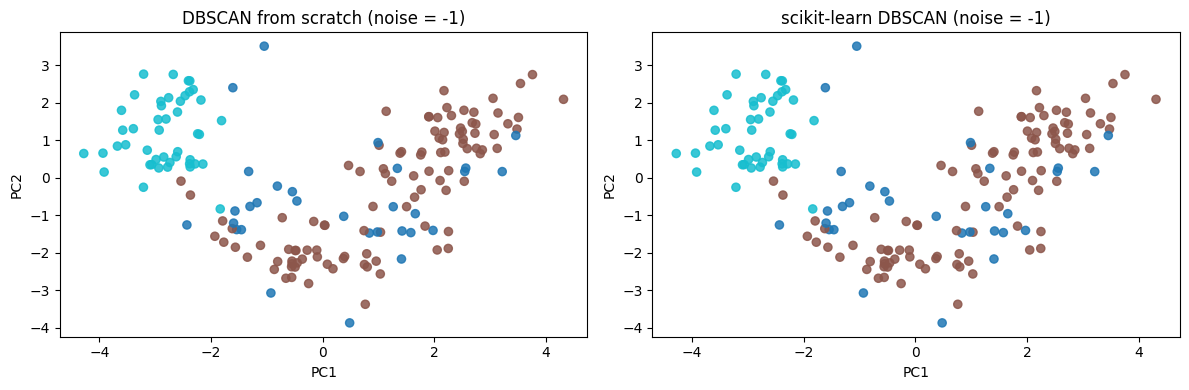

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, labels, title in [
    (ax[0], db_scratch_labels, "DBSCAN from scratch"),
    (ax[1], db_library_labels, "scikit-learn DBSCAN")
]:
    a.scatter(X_pca[:,0], X_pca[:,1], c=labels, cmap="tab10", s=35, alpha=.85)
    a.set_title(title + " (noise = -1)"); a.set_xlabel("PC1"); a.set_ylabel("PC2")
plt.tight_layout(); plt.show()

## 8. Agglomerative hierarchical clustering: scratch and library

A simple single-link agglomerative implementation is included. It maintains a pairwise distance matrix and repeatedly merges the two clusters whose closest members have the smallest distance. The algorithm stops when the requested number of clusters remains. The library comparison uses `AgglomerativeClustering(linkage="single", metric="euclidean")`.

This educational implementation is intentionally straightforward and has cubic-style worst-case work due to repeated cluster-pair searches. It is practical for this small dataset, not a high-performance implementation.

In [19]:
def agglomerative_single_link_scratch(X, n_clusters):
    clusters = [[i] for i in range(len(X))]
    D = np.sqrt(((X[:,None,:] - X[None,:,:])**2).sum(axis=2))
    while len(clusters) > n_clusters:
        best_d = np.inf
        best_pair = None
        for i in range(len(clusters)):
            for j in range(i+1, len(clusters)):
                d = D[np.ix_(clusters[i], clusters[j])].min()
                if d < best_d:
                    best_d, best_pair = d, (i,j)
        i,j = best_pair
        clusters[i] = clusters[i] + clusters[j]
        del clusters[j]
    labels = np.empty(len(X), dtype=int)
    for cid, members in enumerate(clusters):
        labels[members] = cid
    return labels

In [20]:
t0 = time.perf_counter()
agg_scratch_labels = agglomerative_single_link_scratch(X_scaled, best_k)
scratch_agg_time = time.perf_counter()-t0

t0 = time.perf_counter()
try:
    agg_library = AgglomerativeClustering(n_clusters=best_k, linkage="single", metric="euclidean")
except TypeError:  # compatibility with older scikit-learn
    agg_library = AgglomerativeClustering(n_clusters=best_k, linkage="single", affinity="euclidean")
agg_library_labels = agg_library.fit_predict(X_scaled)
library_agg_time = time.perf_counter()-t0

agg_compare = pd.DataFrame([
    {"Implementation":"Agglomerative from scratch", **clustering_metrics(X_scaled, agg_scratch_labels),
     "Time (s)":scratch_agg_time},
    {"Implementation":"scikit-learn Agglomerative", **clustering_metrics(X_scaled, agg_library_labels),
     "Time (s)":library_agg_time}
])
display(agg_compare.round(4))

,Implementation,clusters_excluding_noise,noise_fraction,coverage,silhouette,davies_bouldin,calinski_harabasz,Time (s)
0,Agglomerative from scratch,3,0.0,1.0,0.1827,0.9105,4.0617,5.9177
1,scikit-learn Agglomerative,3,0.0,1.0,0.1827,0.9105,4.0617,0.0019


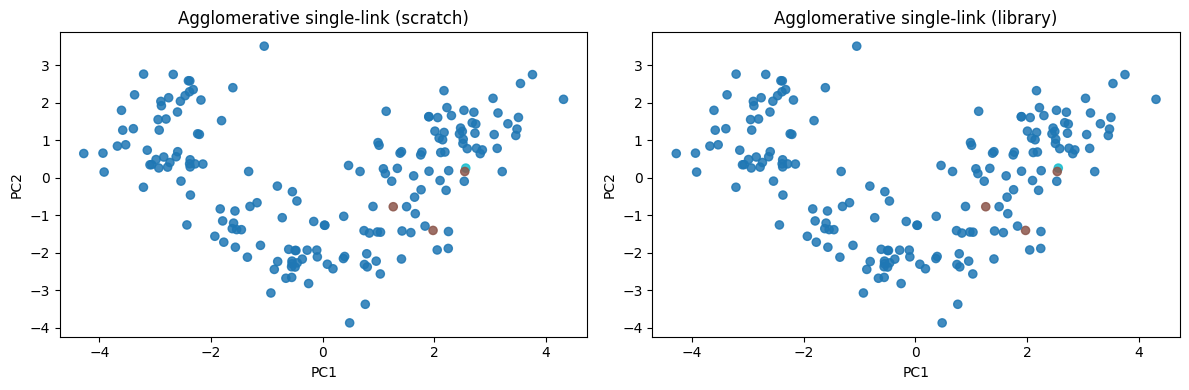

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, labels, title in [
    (ax[0], agg_scratch_labels, "Agglomerative single-link (scratch)"),
    (ax[1], agg_library_labels, "Agglomerative single-link (library)")
]:
    a.scatter(X_pca[:,0], X_pca[:,1], c=labels, cmap="tab10", s=35, alpha=.85)
    a.set_title(title); a.set_xlabel("PC1"); a.set_ylabel("PC2")
plt.tight_layout(); plt.show()

## 9. Overall comparison of algorithms and implementations

The metrics below are internal clustering metrics. Silhouette is maximised; Davies–Bouldin is minimised; Calinski–Harabasz is maximised. For DBSCAN, noise points are excluded from the internal metrics and coverage/noise fraction is shown explicitly. Therefore, DBSCAN scores should not be compared without considering how many observations were discarded as noise.

In [22]:
summary_rows = []
for name, labels, elapsed in [
    ("K-Means scratch", km_scratch["labels"], scratch_km_time),
    ("K-Means library", km_library_labels, library_km_time),
    ("DBSCAN scratch", db_scratch_labels, scratch_db_time),
    ("DBSCAN library", db_library_labels, library_db_time),
    ("Agglomerative scratch", agg_scratch_labels, scratch_agg_time),
    ("Agglomerative library", agg_library_labels, library_agg_time)
]:
    summary_rows.append({"Method":name, **clustering_metrics(X_scaled, labels),
                         "Runtime (s)":elapsed})
summary = pd.DataFrame(summary_rows)
display(summary.round(4))

,Method,clusters_excluding_noise,noise_fraction,coverage,silhouette,davies_bouldin,calinski_harabasz,Runtime (s)
0,K-Means scratch,3,0.0000,1.0000,0.2849,1.3892,70.9400,0.0168
1,K-Means library,3,0.0000,1.0000,0.2849,1.3892,70.9400,0.0161
2,DBSCAN scratch,2,0.1685,0.8315,0.3183,1.2062,73.1147,0.0031
3,DBSCAN library,2,0.1685,0.8315,0.3183,1.2062,73.1147,0.0023
4,Agglomerative scratch,3,0.0000,1.0000,0.1827,0.9105,4.0617,5.9177
5,Agglomerative library,3,0.0000,1.0000,0.1827,0.9105,4.0617,0.0019


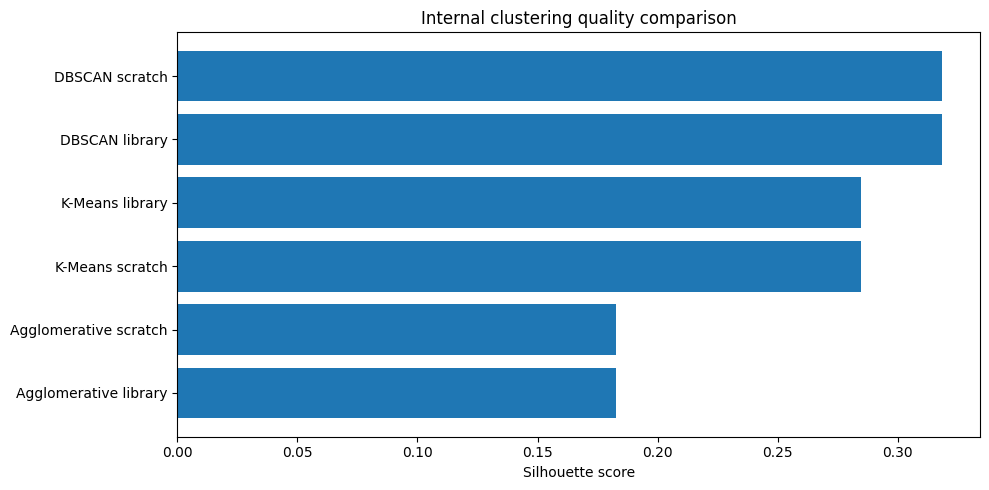

In [23]:
plot_summary = summary.dropna(subset=["silhouette"]).sort_values("silhouette")
plt.figure(figsize=(10,5))
plt.barh(plot_summary["Method"], plot_summary["silhouette"])
plt.xlabel("Silhouette score"); plt.title("Internal clustering quality comparison")
plt.tight_layout(); plt.show()

## 10. Optional post-hoc comparison with known dataset classes

This section is **not part of unsupervised model fitting or parameter selection**. It compares discovered cluster assignments with the dataset's known target classes only after all clustering experiments are complete. Adjusted Rand Index (ARI) and Normalized Mutual Information (NMI) are external comparison measures. They are invariant to arbitrary cluster ID numbering, but a cluster is not necessarily expected to correspond one-to-one with a target class.

Do not use this post-hoc result to claim that the algorithms were supervised. The main evaluation remains the internal metrics above.

In [24]:
external_rows = []
for name, labels in [
    ("K-Means scratch", km_scratch["labels"]),
    ("K-Means library", km_library_labels),
    ("DBSCAN scratch", db_scratch_labels),
    ("DBSCAN library", db_library_labels),
    ("Agglomerative scratch", agg_scratch_labels),
    ("Agglomerative library", agg_library_labels)
]:
    external_rows.append({
        "Method":name,
        "Adjusted Rand Index":adjusted_rand_score(y_reference, labels),
        "Normalized Mutual Information":normalized_mutual_info_score(y_reference, labels)
    })
display(pd.DataFrame(external_rows).round(4))

,Method,Adjusted Rand Index,Normalized Mutual Information
0,K-Means scratch,0.8975,0.8759
1,K-Means library,0.8975,0.8759
2,DBSCAN scratch,0.4129,0.5124
3,DBSCAN library,0.4129,0.5124
4,Agglomerative scratch,-0.0068,0.0349
5,Agglomerative library,-0.0068,0.0349


## 11. Interpretation and when to use each algorithm

### K-Means
Use when clusters are compact, approximately spherical, and a useful number of clusters can be estimated. It is fast and scales well, but requires K and is sensitive to outliers and feature scaling.

### DBSCAN
Use when clusters may have irregular shapes and noise/outliers should be identified explicitly. It does not require K. It is a poor fit when cluster densities vary widely or when the chosen distance metric and radius do not reflect meaningful neighbourhoods.

### Agglomerative hierarchical clustering
Use when a hierarchy of nested groups is useful or when the dataset is small enough for pairwise distance analysis. Single linkage can connect elongated or chained structures, but can also produce chaining where points form long thin clusters.

### From-scratch versus library implementations
Scratch implementations make the mechanics visible and support conceptual understanding. Library implementations are generally more optimised, tested and configurable. Small numerical or label-order differences are normal because cluster IDs are arbitrary and initialisation/implementation details differ. Compare partition quality, not raw cluster ID numbers.

## 12. Limitations, ethics and future improvements

### Limitations
1. The Wine dataset is small and curated; results may not generalise to large or noisy real-world datasets.
2. Standardisation is important for distance-based methods, but it changes the geometry and should be justified for the application.
3. PCA plots show only two dimensions and may hide separation present in the full 13-dimensional space.
4. K-Means assumes centroid-based compact clusters; DBSCAN depends on one global density radius; single-link hierarchical clustering can suffer from chaining.
5. Internal metrics favour particular geometric structures and do not prove that clusters are meaningful to domain experts.
6. Scratch DBSCAN stores a dense pairwise distance matrix, and scratch agglomerative clustering repeatedly searches cluster pairs; these implementations are not suitable for very large datasets.

### Ethical considerations
Clustering can create groupings that appear objective even when they reflect measurement choices, sampling bias or arbitrary parameter settings. Clusters should not be treated as natural categories without domain validation. The Wine dataset is used only for education; clusters should not be interpreted as quality, safety, authenticity or commercial rankings.

### Future work
- Compare K-Means with Gaussian Mixture Models and spectral clustering.
- Test alternative distance metrics and robust scaling.
- Use OPTICS or HDBSCAN for varying-density data.
- Compare complete, average and Ward linkage.
- Use bootstrap resampling to assess cluster stability.
- Analyse feature profiles and cluster centroids to provide domain interpretations.
- Test algorithms on a larger, noisier public dataset and report computational scaling.

## 13. Conclusion

This practical implemented K-Means, DBSCAN and single-link agglomerative clustering both from scratch and with scikit-learn. The Wine dataset's numeric features were standardised, and PCA was used only for visual inspection. K-Means was assessed over several values of K using inertia and silhouette; DBSCAN was assessed over a grid of `eps` and `min_samples` values; hierarchical clustering used a consistent single-linkage definition in both implementations.

The best clustering method should be selected using multiple internal metrics, cluster sizes, DBSCAN coverage and visual/domain interpretation—not a single score alone. Scratch implementations demonstrate the algorithmic steps, while library versions provide robust and efficient reference implementations.

### References
1. Scikit-learn Wine dataset: https://scikit-learn.org/stable/datasets/toy_dataset.html#wine-recognition-dataset
2. KMeans: https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html
3. DBSCAN: https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html
4. AgglomerativeClustering: https://scikit-learn.org/stable/modules/generated/sklearn.cluster.AgglomerativeClustering.html
5. Clustering performance evaluation: https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation

### Assignment checklist
- [x] Real-world dataset selected and described
- [x] Feature scaling and exploratory analysis
- [x] K-Means from scratch and library
- [x] DBSCAN from scratch and library
- [x] Agglomerative clustering from scratch and library
- [x] Parameter selection and sensitivity analysis
- [x] Silhouette, Davies–Bouldin and Calinski–Harabasz metrics
- [x] PCA visualisations and cluster/noise summaries
- [x] Comparison, interpretation, limitations, ethics and future work